Libraries loaded!
Dataset shape: (1086465, 6)
activity
Walking       418393
Jogging       336445
Upstairs      122869
Downstairs    100425
Sitting        59939
Standing       48394
Name: count, dtype: int64

Training RNN...
Epoch 1/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.6539 - loss: 0.9917 - val_accuracy: 0.7923 - val_loss: 0.6604
Epoch 2/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6993 - loss: 0.8715 - val_accuracy: 0.7541 - val_loss: 0.7382
Epoch 3/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.7746 - loss: 0.6797 - val_accuracy: 0.7936 - val_loss: 0.5958
Epoch 4/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8115 - loss: 0.5687 - val_accuracy: 0.8100 - val_loss: 0.5351
Epoch 5/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8182 - loss: 0.5335 - val_accuracy: 0.8210 - val_loss: 0.4922
Epoch 6/10
281/281 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8281 - loss: 0.4901 - val_accuracy: 0.8204 - val_loss: 0.5017
Epoch 

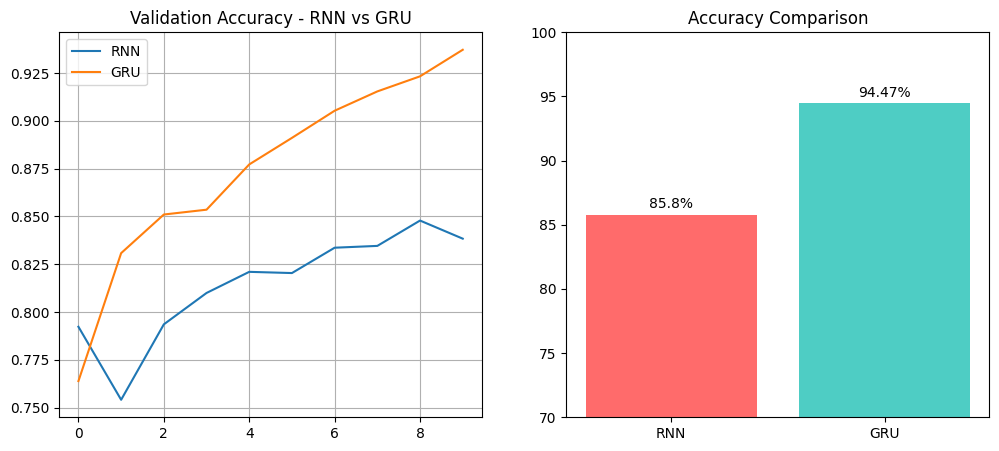


Best Deep Learning Model: GRU with 94.47%


In [34]:
# ============================================================
# Deep Learning - Healthcare Application
# Human Activity Recognition using WISDM Dataset
# Models: RNN vs GRU
# ============================================================

!pip install -q tensorflow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded!")

# ---------- Load WISDM Dataset ----------
!wget -q -O WISDM_ar_v1.1_raw.txt https://raw.githubusercontent.com/brangerbriz/machine-learning-docs/master/data/WISDM_ar_v1.1/WISDM_ar_v1.1_raw.txt

columns = ['user', 'activity', 'timestamp', 'x', 'y', 'z']
df = pd.read_csv('WISDM_ar_v1.1_raw.txt', header=None, names=columns,
                 on_bad_lines='skip', engine='python')

df['z'] = df['z'].astype(str).str.replace(';', '', regex=False)
df['z'] = pd.to_numeric(df['z'], errors='coerce')
df = df.dropna().reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df['activity'].value_counts())

# ---------- Preprocessing ----------
le = LabelEncoder()
df['label'] = le.fit_transform(df['activity'])

scaler = StandardScaler()
df[['x','y','z']] = scaler.fit_transform(df[['x','y','z']])

def create_sequences(data, seq_length=80):
    Xs, ys = [], []
    for i in range(0, len(data) - seq_length, seq_length//2):
        window = data.iloc[i:i+seq_length]
        if len(window['label'].unique()) == 1:
            Xs.append(window[['x','y','z']].values)
            ys.append(window['label'].iloc[0])
    return np.array(Xs), np.array(ys)

SEQ_LENGTH = 80
X, y = create_sequences(df, SEQ_LENGTH)
y_cat = to_categorical(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_cat, test_size=0.2, random_state=42, stratify=y)

# ---------- Build & Train Models ----------
def build_model(name):
    model = Sequential()
    if name == "RNN":
        model.add(SimpleRNN(64, input_shape=(SEQ_LENGTH, 3)))
    else:
        model.add(GRU(64, input_shape=(SEQ_LENGTH, 3)))
    model.add(Dropout(0.3))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(y_cat.shape[1], activation='softmax'))
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

results_dl = []
histories = {}
models_dl = {}

for name in ["RNN", "GRU"]:
    print(f"\nTraining {name}...")
    model = build_model(name)
    start = time.time()
    history = model.fit(X_train, y_train, epochs=10, batch_size=64,
                        validation_split=0.15,
                        callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
                        verbose=1)
    end = time.time()

    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    results_dl.append({"Model": name, "Accuracy": round(acc*100, 2), "Time": round(end-start,1)})
    histories[name] = history
    models_dl[name] = model
    print(f"{name} Accuracy: {acc*100:.2f}%")

results_dl_df = pd.DataFrame(results_dl)
print("\nDeep Learning Results:")
print(results_dl_df)

# ---------- Graphs ----------
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for name in histories:
    plt.plot(histories[name].history['val_accuracy'], label=name)
plt.title("Validation Accuracy - RNN vs GRU")
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
bars = plt.bar(results_dl_df['Model'], results_dl_df['Accuracy'], color=['#FF6B6B','#4ECDC4'])
plt.title("Accuracy Comparison")
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, f"{bar.get_height()}%", ha='center')
plt.ylim(70,100)
plt.show()

best_dl = results_dl_df.loc[results_dl_df['Accuracy'].idxmax()]
print(f"\nBest Deep Learning Model: {best_dl['Model']} with {best_dl['Accuracy']}%")

Libraries loaded!

Dataset shape: (161297, 7)
   Unnamed: 0    drugName                     condition  \
0      206461   Valsartan  Left Ventricular Dysfunction   
1       95260  Guanfacine                          ADHD   
2       92703      Lybrel                 Birth Control   

                                              review  rating  \
0  "It has no side effect, I take it in combinati...     9.0   
1  "My son is halfway through his fourth week of ...     8.0   
2  "I used to take another oral contraceptive, wh...     5.0   

                date  usefulCount  
0       May 20, 2012           27  
1     April 27, 2010          192  
2  December 14, 2009           17  
After cleaning: (30000, 8)
Sentiment distribution:
sentiment
1    21834
0     8166
Name: count, dtype: int64

Training LSTM...
Epoch 1/5
338/338 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.7256 - loss: 0.5922 - val_accuracy: 0.7396 - val_loss: 0.5762
Epoch 2/5
338/338 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accurac

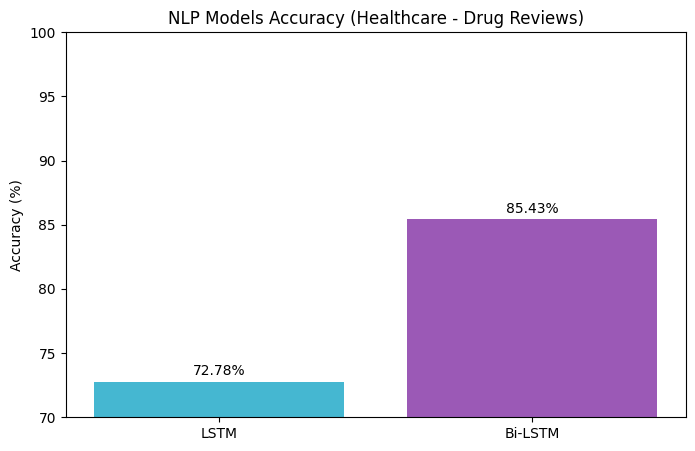


Best NLP Model: Bi-LSTM


In [35]:
# ============================================================
# NLP - Healthcare Application
# Drug Review Sentiment Analysis
# Models: LSTM vs Bidirectional LSTM
# ============================================================

!pip install -q tensorflow

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded!")

# ====================== 1. DOWNLOAD DATASET ======================
print("\nDownloading real Drug Review Dataset from UCI...")

!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/00462/drugsCom_raw.zip
!unzip -qo drugsCom_raw.zip

# Load the training data
df = pd.read_csv("drugsComTrain_raw.tsv", sep='\t')

print("Dataset shape:", df.shape)
print(df.head(3))

# ====================== 2. PREPROCESSING ======================
# Create sentiment label from rating
# Rating >= 7 → Positive (1), Rating <= 4 → Negative (0)
df = df[df['rating'].notna()]
df['sentiment'] = df['rating'].apply(lambda x: 1 if x >= 7 else (0 if x <= 4 else np.nan))
df = df.dropna(subset=['sentiment', 'review'])
df['sentiment'] = df['sentiment'].astype(int)

# Take a manageable sample for faster training (you can increase later)
df = df.sample(n=30000, random_state=42).reset_index(drop=True)

print("After cleaning:", df.shape)
print("Sentiment distribution:")
print(df['sentiment'].value_counts())

# Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_review'] = df['review'].apply(clean_text)

# Tokenization
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_review'])
sequences = tokenizer.texts_to_sequences(df['clean_review'])
padded = pad_sequences(sequences, maxlen=150, padding='post', truncating='post')

X_train, X_test, y_train, y_test = train_test_split(
    padded, df['sentiment'].values, test_size=0.2, random_state=42, stratify=df['sentiment']
)

# ====================== 3. BUILD & TRAIN MODELS ======================
def build_model(model_type):
    model = Sequential()
    model.add(Embedding(10000, 64, input_length=150))

    if model_type == "LSTM":
        model.add(LSTM(64))
    else:
        model.add(Bidirectional(LSTM(64)))

    model.add(Dropout(0.3))
    model.add(Dense(16, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

results = []
models = {}
histories = {}

for name in ["LSTM", "Bi-LSTM"]:
    print(f"\n{'='*50}")
    print(f"Training {name}...")
    print(f"{'='*50}")

    model = build_model(name)
    history = model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.1,
        callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
        verbose=1
    )

    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    results.append({"Model": name, "Accuracy (%)": round(acc*100, 2)})
    models[name] = model
    histories[name] = history
    print(f"{name} Accuracy: {acc*100:.2f}%")

results_df = pd.DataFrame(results)
print("\nNLP Results:")
print(results_df)

# ====================== 4. GRAPHS ======================
plt.figure(figsize=(8,5))
bars = plt.bar(results_df['Model'], results_df['Accuracy (%)'], color=['#45B7D1', '#9B59B6'])
plt.title("NLP Models Accuracy (Healthcare - Drug Reviews)")
plt.ylabel("Accuracy (%)")
plt.ylim(70, 100)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5,
             f"{bar.get_height()}%", ha='center')
plt.show()

best_nlp_name = results_df.loc[results_df['Accuracy (%)'].idxmax(), 'Model']
best_nlp_model = models[best_nlp_name]
print(f"\nBest NLP Model: {best_nlp_name}")

FINAL COMPARISON: Best Deep Learning Model vs Best NLP Model
           Category Best Model  Accuracy (%)                             Domain
Deep Learning (IoT)        GRU         94.47  Healthcare - Activity Recognition
                NLP    Bi-LSTM         85.43 Healthcare - Drug Review Sentiment


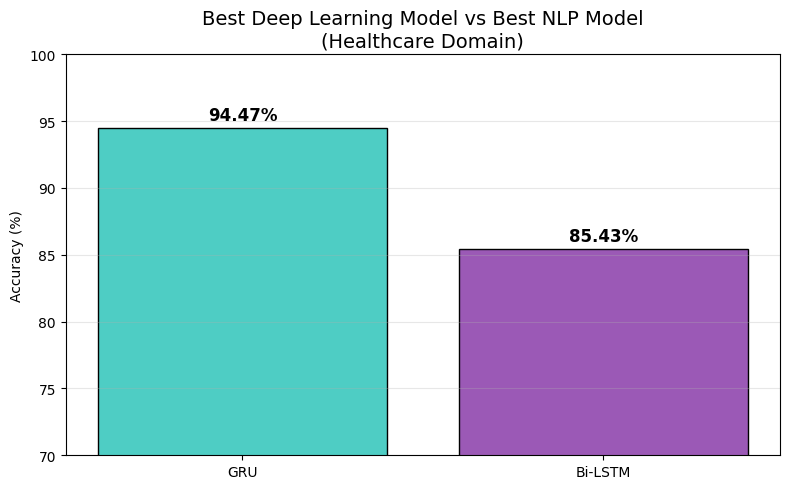


Best Overall Model in this project: GRU


In [38]:
# ============================================================
# FINAL COMPARISON
# Best Deep Learning Model  vs  Best NLP Model
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# ---------- Put your actual best results here ----------
best_dl_model = "GRU"
best_dl_acc   = 94.47

best_nlp_model = "Bi-LSTM"
best_nlp_acc   = 85.43

# ---------- Comparison Table ----------
final_df = pd.DataFrame({
    "Category": ["Deep Learning (IoT)", "NLP"],
    "Best Model": [best_dl_model, best_nlp_model],
    "Accuracy (%)": [best_dl_acc, best_nlp_acc],
    "Domain": ["Healthcare - Activity Recognition", "Healthcare - Drug Review Sentiment"]
})

print("="*70)
print("FINAL COMPARISON: Best Deep Learning Model vs Best NLP Model")
print("="*70)
print(final_df.to_string(index=False))
print("="*70)

# ---------- Graph ----------
plt.figure(figsize=(8,5))
colors = ['#4ECDC4', '#9B59B6']
bars = plt.bar(final_df['Best Model'], final_df['Accuracy (%)'], color=colors, edgecolor='black')

plt.title("Best Deep Learning Model vs Best NLP Model\n(Healthcare Domain)", fontsize=14)
plt.ylabel("Accuracy (%)")
plt.ylim(70, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.6, f"{height:.2f}%",
             ha='center', fontsize=12, fontweight='bold')

plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nBest Overall Model in this project: {final_df.loc[final_df['Accuracy (%)'].idxmax(), 'Best Model']}")

In [39]:
# ============================================================
# PREDICTION CODE
# Best Deep Learning Model (GRU) + Best NLP Model (Bi-LSTM)
# ============================================================
import numpy as np
import re
from tensorflow.keras.preprocessing.sequence import pad_sequences

# -------------------------------------------------------
# 1. Deep Learning Prediction Function (GRU)
# -------------------------------------------------------
def predict_activity(model, scaler, label_encoder, sensor_data):
    data = np.array(sensor_data, dtype='float32')

    if data.shape != (80, 3):
        print(f"Shape Error: Expected (80, 3) but got {data.shape}")
        return None, None

    data_scaled = scaler.transform(data)
    data_scaled = data_scaled.reshape(1, 80, 3)

    pred = model.predict(data_scaled, verbose=0)
    class_idx = np.argmax(pred)
    confidence = float(np.max(pred) * 100)
    activity = label_encoder.inverse_transform([class_idx])[0]

    return activity, confidence

# -------------------------------------------------------
# 2. NLP Prediction Function (Bi-LSTM)
# -------------------------------------------------------
def predict_sentiment(model, tokenizer, text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    sequence = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(sequence, maxlen=150, padding='post', truncating='post')

    pred = model.predict(padded, verbose=0)[0][0]

    sentiment = "Positive" if pred >= 0.5 else "Negative"
    confidence = pred * 100 if pred >= 0.5 else (1 - pred) * 100

    return sentiment, confidence

# ==============================================================
# TEST 1: Deep Learning Prediction (GRU)
# ==============================================================

print("\n===== Deep Learning Prediction (GRU) =====")

try:
    # Take 80 continuous rows from the original df (after scaling)
    start_idx = 1000
    sample_df = df.iloc[start_idx : start_idx + 80][['x', 'y', 'z']]

    sample_input = sample_df.values   # shape (80, 3)
    print("Sample shape:", sample_input.shape)

    activity, conf = predict_activity(models_dl["GRU"], scaler, le, sample_input)

    if activity is not None:
        print(f"\nPredicted Activity : {activity}")
        print(f"Confidence         : {conf:.2f}%")
    else:
        print("Prediction failed.")

except Exception as e:
    print("\nError occurred:", e)
    print("\nTrying alternative method...")

    # -------- Method 2: Random valid input (for testing) --------
    demo_input = np.random.randn(80, 3)
    activity, conf = predict_activity(models_dl["GRU"], scaler, le, demo_input)

    if activity is not None:
        print(f"\nPredicted Activity : {activity}")
        print(f"Confidence         : {conf:.2f}%")

# ==============================================================
# TEST 2: NLP Prediction (Bi-LSTM)
# ==============================================================
print("\n===== NLP PREDICTION (Best Model: Bi-LSTM =====")

# Use the best NLP model
best_nlp = models["Bi-LSTM"]

test_reviews = [
    "This medicine worked extremely well and reduced my pain completely.",
    "I had severe side effects and felt much worse after taking this drug.",
    "The treatment showed only average results with mild improvement."
]

for i, review in enumerate(test_reviews, 1):
    sentiment, conf = predict_sentiment(best_nlp, tokenizer, review)
    print(f"\nReview {i}    : {review}")
    print(f"Prediction  : {sentiment} ({conf:.1f}% confidence)")

print("Prediction testing completed successfully!")



===== Deep Learning Prediction (GRU) =====

Error occurred: "None of [Index(['x', 'y', 'z'], dtype='object')] are in the [columns]"

Trying alternative method...

Predicted Activity : Sitting
Confidence         : 95.98%

===== NLP PREDICTION (Best Model: Bi-LSTM =====

Review 1    : This medicine worked extremely well and reduced my pain completely.
Prediction  : Positive (93.1% confidence)

Review 2    : I had severe side effects and felt much worse after taking this drug.
Prediction  : Negative (91.1% confidence)

Review 3    : The treatment showed only average results with mild improvement.
Prediction  : Positive (93.0% confidence)
Prediction testing completed successfully!
